# <span style="font-weight:bold; font-size:1.1em">Density Plots</span>

<span style="font-weight:bold; font-size:1.2em">To find descriptive statistics, the functions<center><span style="font-weight:bold;font-size:1.2em;color:blue;">density()</span> <span style="color:red;"> and </span> <span style="color:blue; font-weight:bold; font-size:1.2em">densities()</span></center></br> <span style="font-weight:bold; font-size:1.2em"> work with table/column input, but </span> <span style="color:blue; font-weight:bold; font-size:1.2em">density()</span> <span style="font-weight:bold; font-size:1.2em"> can also work with array input.</span></br>

These functions allow students to intuitvely create density plots at every step of the course. They possess the flexibility to create a singled density plot or multiple superimposed density plots based upon a grouping variable.

### <span style="font-weight:bold; font-size:1.1em">Run the cell below without changing it to load the tools we need.</span>

In [16]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from scipy.stats import gaussian_kde

N = make_array(67, 65, 66, 63, 60, 62, 64, 68, 71, 69, 65, 62, 59, 58, 61,
               63, 66, 62, 59, 57, 55, 58, 60, 63, 62, 58, 56, 54, 57, 59)
pers = Table.read_table('http://faculty.ung.edu/rsinn/personality.csv')
births = Table.read_table('https://faculty.ung.edu/rsinn/data/baby.csv')

## <span style="font-weight:bold; font-size:1.1em">The density() Function</span>

The code below creates the **density()** function which which micmic R's density plot because the parameters **adjust** and **cut** are set to specific values and the **scott** method is utilized. The density plot can be used along with or instead of a histogram to determine shape.

1. For use with an array:<center><span style="color:blue; font-weight:bold; font-size:1.25em">describe(array_name)</span></center>
2. For use with a table and numeric data column:<center><span style="color:blue; font-weight:bold; font-size:1.25em">describe(table_name, column_name)</span></center>

The <span style="color:red; font-weight:bold; font-size:1.1em">scott</span> method calculates a scaling factor based on the number of data points (n) and the number of dimensions (d) in your dataset:
$$\text{factor}=n^{-\frac{1}{d+4}}$$
In **scipy.stats.gaussian_kde**, this factor scales the data's covariance matrix to determine the actual shape and spread (bandwidth) of the Gaussian kernels:
$$\text{kernel\ covariance}=\text{factor}^{2}\times \text{cov}(\text{dataset})$$
The **scott** method acts as a fast <span style="color:blue; font-weight:bold">rule-of-thumb</span> estimator that works well for data that is roughly Gaussian (normal).

In [17]:
def density(data, num = None):
  if isinstance(data, Table):
    sns.kdeplot( data = data.column(num), bw_method="scott", bw_adjust=0.75, cut=3 )
    plots.title(f'Density Plot of {num}')  ;  plots.show()
  else:
    if num == None:
      num = 'Variable'
      sns.kdeplot( data = data, bw_method="scott", bw_adjust=0.75, cut=3 )
      plots.title(f'Density Plot of {num}')
      plots.show()
    else:
      sns.kdeplot( data = data, bw_method="scott", bw_adjust=0.75, cut=3 )
      plots.title(f'Density Plot of {num}')  ;  plots.show()
  return

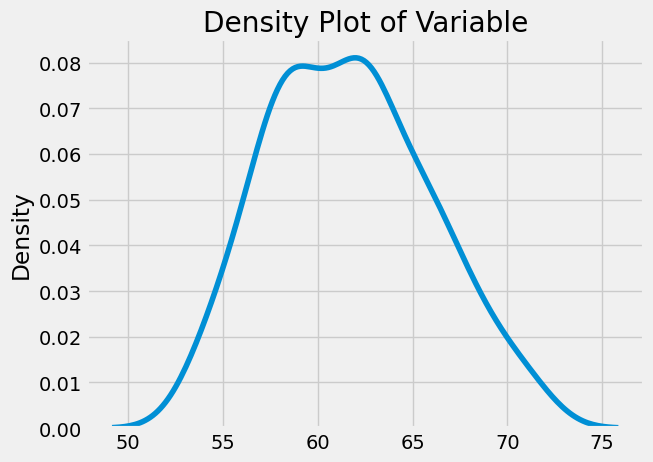

In [18]:
density(N)

## <span style="font-weight:bold; font-size:1.1em">The densities() Function</span>

The code below creates the **densities()** function which provides multiple density plots superimposed over one another.<center><span style="color:blue; font-weight:bold; font-size:1.25em">densities(table_name, num_column, group_column)</span></center>

In [19]:
def densities(tab, var, group_var):
  groups = tab.column(group_var) ;  unique_groups = np.unique(groups)  ;  plots.figure()
  for g in unique_groups:
    # Filter data for the current group
    mask = (groups == g)
    x = tab.column(var)[mask]   
    kde = gaussian_kde(x)
    x_grid = np.linspace(x.min() - 1, x.max() + 1, 512)  ;    plots.plot(x_grid, kde(x_grid), label=str(g))   
  plots.title(f'Density Plot of {var} by {group_var}')  ;  plots.xlabel(f'{var}')  ;  plots.ylabel('Density')
  plots.legend()  ;  plots.show()
  return

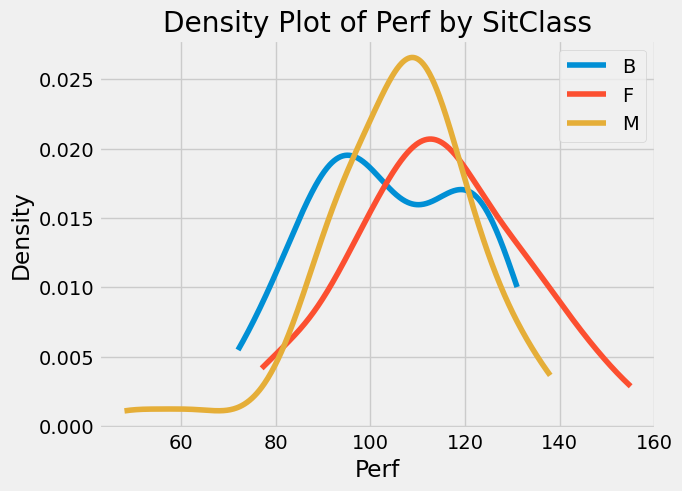

In [20]:
densities(pers,'Perf','SitClass')